In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../data/raw/airline_flights_dataset.csv")

df.head()

,Flight_ID,Flight_Date,Airline,Origin_City,Destination_City,Travel_Class,Scheduled_Duration_Min,Delay_Minutes,Distance_KM,Ticket_Price_INR,Seats_Booked,Total_Seats,Passenger_Rating,Flight_Status
0,FLT-9313,2024-01-01,Falcon Airways,Jaipur,Kolkata,Economy,188,30,1812,12196.69,128,205,4,On Time
1,FLT-11160,2024-01-01,Air Bharat,Goa,Kochi,Economy,96,66,2257,10807.94,191,225,4,On Time
2,FLT-10032,2024-01-01,Coastal Air,Jaipur,Bengaluru,Premium Economy,136,79,1848,14468.78,96,194,4,Delayed
3,FLT-10190,2024-01-01,IndiGo Air,Lucknow,Chennai,Economy,67,114,2139,16391.74,75,181,4,On Time
4,FLT-9474,2024-01-01,Air Bharat,Goa,Chennai,Premium Economy,110,80,549,25549.52,74,151,4,Cancelled


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 4000
Columns: 14


In [6]:
df.columns

Index(['Flight_ID', 'Flight_Date', 'Airline', 'Origin_City',
       'Destination_City', 'Travel_Class', 'Scheduled_Duration_Min',
       'Delay_Minutes', 'Distance_KM', 'Ticket_Price_INR', 'Seats_Booked',
       'Total_Seats', 'Passenger_Rating', 'Flight_Status'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Flight_ID               4000 non-null   object 
 1   Flight_Date             4000 non-null   object 
 2   Airline                 4000 non-null   object 
 3   Origin_City             4000 non-null   object 
 4   Destination_City        4000 non-null   object 
 5   Travel_Class            4000 non-null   object 
 6   Scheduled_Duration_Min  4000 non-null   int64  
 7   Delay_Minutes           4000 non-null   int64  
 8   Distance_KM             4000 non-null   int64  
 9   Ticket_Price_INR        4000 non-null   float64
 10  Seats_Booked            4000 non-null   int64  
 11  Total_Seats             4000 non-null   int64  
 12  Passenger_Rating        4000 non-null   int64  
 13  Flight_Status           4000 non-null   object 
dtypes: float64(1), int64(6), object(7)
memor

In [8]:
df.describe()

,Scheduled_Duration_Min,Delay_Minutes,Distance_KM,Ticket_Price_INR,Seats_Booked,Total_Seats,Passenger_Rating
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,142.603250,89.546500,1325.546500,23357.600070,134.470500,199.481750,3.014250
std,55.115377,51.832572,678.480716,12365.637516,49.752286,28.983309,1.397689
min,45.000000,0.000000,150.000000,2004.000000,50.000000,150.000000,1.000000
25%,95.000000,44.000000,746.750000,12450.920000,90.000000,174.000000,2.000000
50%,143.000000,90.000000,1332.000000,23401.765000,134.000000,200.000000,3.000000
75%,189.000000,134.000000,1917.250000,33950.612500,178.000000,224.000000,4.000000
max,239.000000,179.000000,2499.000000,44990.870000,219.000000,249.000000,5.000000


In [9]:
df.isnull().sum()

Flight_ID                 0
Flight_Date               0
Airline                   0
Origin_City               0
Destination_City          0
Travel_Class              0
Scheduled_Duration_Min    0
Delay_Minutes             0
Distance_KM               0
Ticket_Price_INR          0
Seats_Booked              0
Total_Seats               0
Passenger_Rating          0
Flight_Status             0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (4000, 14)


In [12]:
for column in df.columns:
    print("\n", column)
    print(df[column].nunique())


 Flight_ID
4000

 Flight_Date
366

 Airline
6

 Origin_City
10

 Destination_City
10

 Travel_Class
3

 Scheduled_Duration_Min
195

 Delay_Minutes
180

 Distance_KM
1930

 Ticket_Price_INR
3996

 Seats_Booked
170

 Total_Seats
100

 Passenger_Rating
5

 Flight_Status
3


In [13]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

categorical_columns

Index(['Flight_ID', 'Flight_Date', 'Airline', 'Origin_City',
       'Destination_City', 'Travel_Class', 'Flight_Status'],
      dtype='object')

In [14]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

numerical_columns

Index(['Scheduled_Duration_Min', 'Delay_Minutes', 'Distance_KM',
       'Ticket_Price_INR', 'Seats_Booked', 'Total_Seats', 'Passenger_Rating'],
      dtype='object')

In [15]:
if "Airline" in df.columns:

    airline_counts = df["Airline"].value_counts()

    print(airline_counts)

Airline
SkyJet            690
BlueWing          680
Air Bharat        678
Coastal Air       675
IndiGo Air        639
Falcon Airways    638
Name: count, dtype: int64


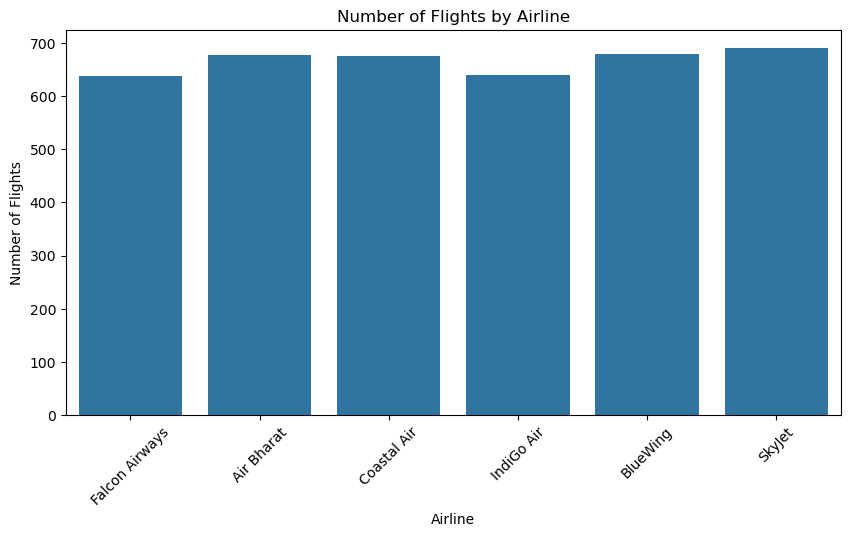

In [16]:
if "Airline" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x="Airline"
    )

    plt.title("Number of Flights by Airline")
    plt.xlabel("Airline")
    plt.ylabel("Number of Flights")
    plt.xticks(rotation=45)

    plt.show()

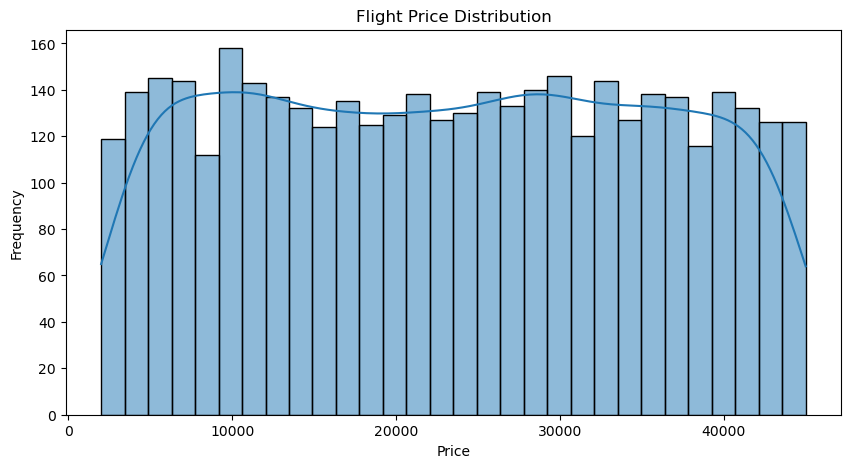

In [25]:
if "Ticket_Price_INR" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["Ticket_Price_INR"],
        bins=30,
        kde=True
    )

    plt.title("Flight Price Distribution")
    plt.xlabel("Price")
    plt.ylabel("Frequency")

    plt.show()

In [26]:
if "Airline" in df.columns and "Ticket_Price_INR" in df.columns:

    avg_price = (
        df.groupby("Airline")["Ticket_Price_INR"]
        .mean()
        .sort_values(ascending=False)
    )

    print(avg_price)

Airline
IndiGo Air        23860.678905
Air Bharat        23796.692257
SkyJet            23503.018290
Coastal Air       23481.394652
BlueWing          22841.870574
Falcon Airways    22648.547194
Name: Ticket_Price_INR, dtype: float64


In [27]:
df.columns

Index(['Flight_ID', 'Flight_Date', 'Airline', 'Origin_City',
       'Destination_City', 'Travel_Class', 'Scheduled_Duration_Min',
       'Delay_Minutes', 'Distance_KM', 'Ticket_Price_INR', 'Seats_Booked',
       'Total_Seats', 'Passenger_Rating', 'Flight_Status'],
      dtype='object')

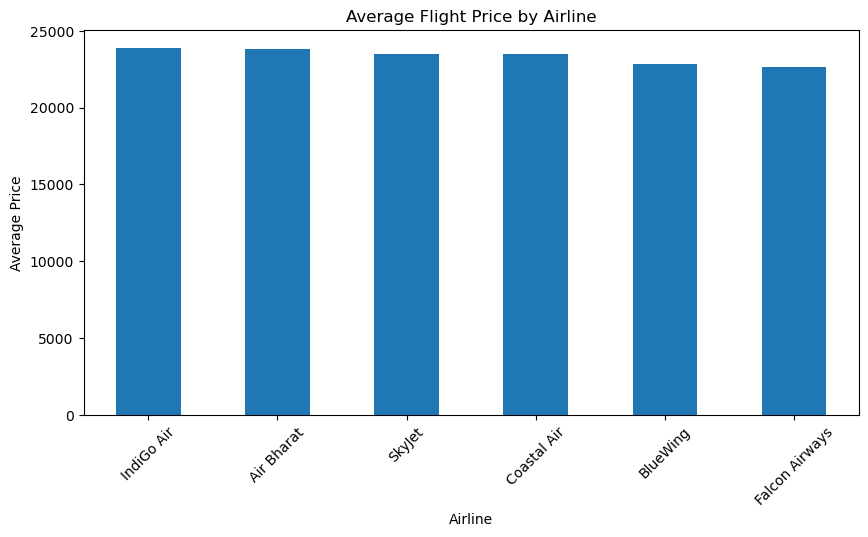

In [28]:
if "Airline" in df.columns and "Ticket_Price_INR" in df.columns:

    plt.figure(figsize=(10, 5))

    avg_price.plot(kind="bar")

    plt.title("Average Flight Price by Airline")
    plt.xlabel("Airline")
    plt.ylabel("Average Price")
    plt.xticks(rotation=45)

    plt.show()

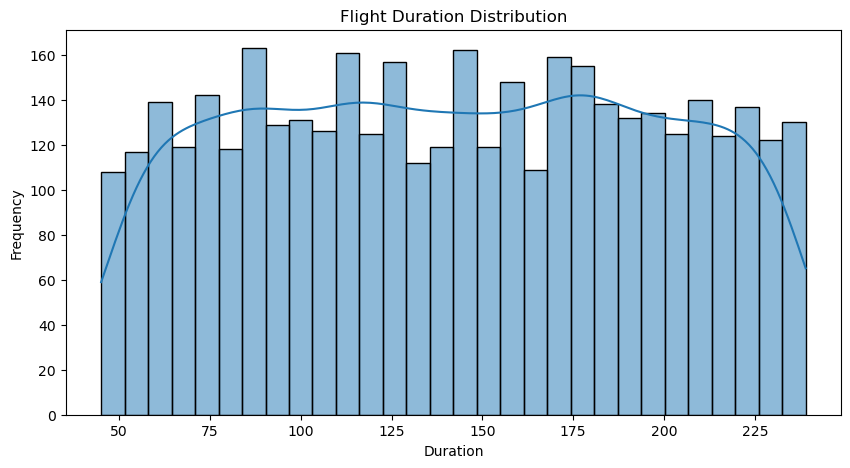

In [30]:
if "Scheduled_Duration_Min" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["Scheduled_Duration_Min"],
        bins=30,
        kde=True
    )

    plt.title("Flight Duration Distribution")
    plt.xlabel("Duration")
    plt.ylabel("Frequency")

    plt.show()

In [32]:
if "Destination_City" in df.columns:

    destination_counts = df["Destination_City"].value_counts()

    print(destination_counts.head(10))

Destination_City
Kolkata      429
Mumbai       425
Chennai      416
Kochi        409
Goa          407
Delhi        400
Lucknow      394
Jaipur       386
Bengaluru    372
Hyderabad    362
Name: count, dtype: int64


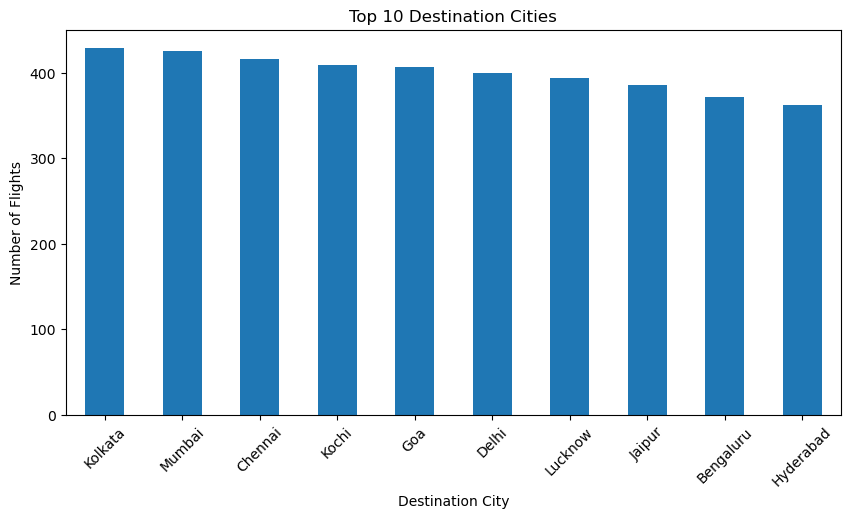

In [33]:
if "Destination_City" in df.columns:

    plt.figure(figsize=(10, 5))

    df["Destination_City"].value_counts().head(10).plot(
        kind="bar"
    )

    plt.title("Top 10 Destination Cities")
    plt.xlabel("Destination City")
    plt.ylabel("Number of Flights")
    plt.xticks(rotation=45)

    plt.show()

In [34]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation

,Scheduled_Duration_Min,Delay_Minutes,Distance_KM,Ticket_Price_INR,Seats_Booked,Total_Seats,Passenger_Rating
Scheduled_Duration_Min,1.000000,-0.020528,0.011963,-0.026367,0.019671,-0.014122,0.000460
Delay_Minutes,-0.020528,1.000000,-0.006827,0.018516,0.005715,0.015503,-0.005406
Distance_KM,0.011963,-0.006827,1.000000,0.005505,0.021875,0.016335,0.025379
Ticket_Price_INR,-0.026367,0.018516,0.005505,1.000000,-0.023141,-0.002307,-0.023822
Seats_Booked,0.019671,0.005715,0.021875,-0.023141,1.000000,0.006579,-0.019400
Total_Seats,-0.014122,0.015503,0.016335,-0.002307,0.006579,1.000000,-0.008058
Passenger_Rating,0.000460,-0.005406,0.025379,-0.023822,-0.019400,-0.008058,1.000000


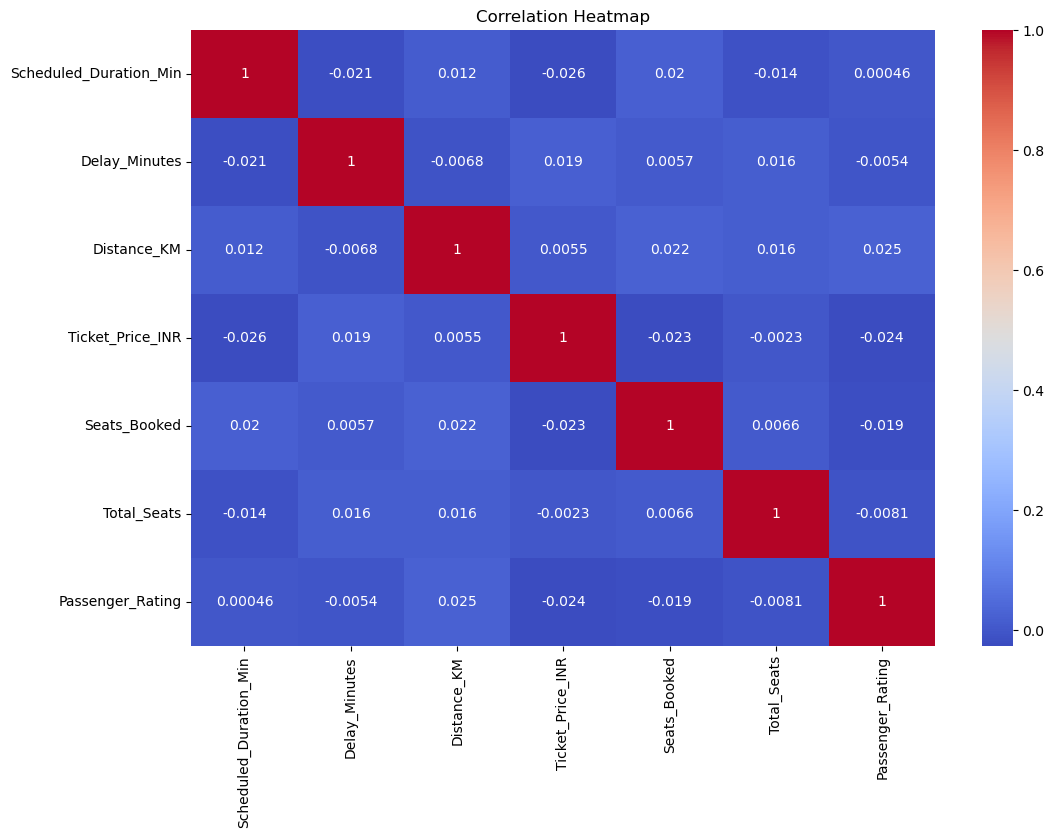

In [35]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

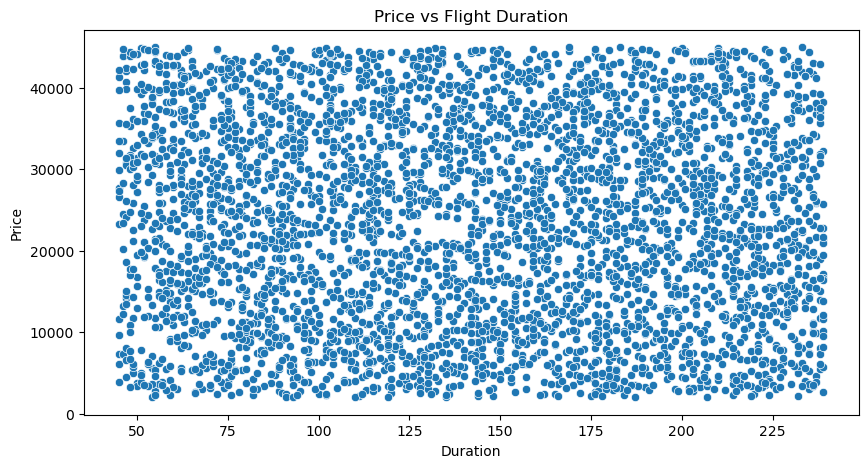

In [37]:
if "Ticket_Price_INR" in df.columns and "Scheduled_Duration_Min" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.scatterplot(
        data=df,
        x="Scheduled_Duration_Min",
        y="Ticket_Price_INR"
    )

    plt.title("Price vs Flight Duration")
    plt.xlabel("Duration")
    plt.ylabel("Price")

    plt.show()

In [38]:
df.columns

Index(['Flight_ID', 'Flight_Date', 'Airline', 'Origin_City',
       'Destination_City', 'Travel_Class', 'Scheduled_Duration_Min',
       'Delay_Minutes', 'Distance_KM', 'Ticket_Price_INR', 'Seats_Booked',
       'Total_Seats', 'Passenger_Rating', 'Flight_Status'],
      dtype='object')

In [39]:
df.head()

,Flight_ID,Flight_Date,Airline,Origin_City,Destination_City,Travel_Class,Scheduled_Duration_Min,Delay_Minutes,Distance_KM,Ticket_Price_INR,Seats_Booked,Total_Seats,Passenger_Rating,Flight_Status
0,FLT-9313,2024-01-01,Falcon Airways,Jaipur,Kolkata,Economy,188,30,1812,12196.69,128,205,4,On Time
1,FLT-11160,2024-01-01,Air Bharat,Goa,Kochi,Economy,96,66,2257,10807.94,191,225,4,On Time
2,FLT-10032,2024-01-01,Coastal Air,Jaipur,Bengaluru,Premium Economy,136,79,1848,14468.78,96,194,4,Delayed
3,FLT-10190,2024-01-01,IndiGo Air,Lucknow,Chennai,Economy,67,114,2139,16391.74,75,181,4,On Time
4,FLT-9474,2024-01-01,Air Bharat,Goa,Chennai,Premium Economy,110,80,549,25549.52,74,151,4,Cancelled


In [42]:
df.to_csv(
    "../data/processed/processed_airline_flights.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [45]:
print("KEY INSIGHTS")


if "Airline" in df.columns:
    print(
        "1. Total Airlines:",
        df["Airline"].nunique()
    )

if "Price" in df.columns:
    print(
        "2. Average Flight Price:",
        round(df["Price"].mean(), 2)
    )

if "Duration" in df.columns:
    print(
        "3. Average Flight Duration:",
        round(df["Duration"].mean(), 2)
    )

if "Airline" in df.columns:
    print(
        "4. Most Frequent Airline:",
        df["Airline"].value_counts().idxmax()
    )

if "Source" in df.columns:
    print(
        "5. Most Common Source City:",
        df["Source"].value_counts().idxmax()
    )

if "Destination" in df.columns:
    print(
        "6. Most Common Destination City:",
        df["Destination"].value_counts().idxmax()
    )

KEY INSIGHTS
1. Total Airlines: 6
4. Most Frequent Airline: SkyJet
